In [1]:
%load_ext jupyter_black

In [2]:
# SPLITS = 'random',
# SPLITS = 'scaffold',
# SPLITS = 'tanimoto',
SPLITS = "temporal"

# Index


<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 4>
1. <a href="#Imports">Imports</a><br>
2. <a href="#Data-preparation">Data preparation</a><br>
3. <a href="#Model-training-&-test-set-prediction">Model training & test set prediction</a><br>
4. <a href="#Domain-of-applicability">Domain of applicability</a><br>
5. <a href="#UMAP">UMAP</a><br>

</font>
</div>

# Imports

In [3]:
import matplotlib.pyplot as plt
import nest_asyncio
import numpy as np
import pandas as pd
import scipy.stats as ss
import seaborn as sns
import stan

from itertools import combinations
from patsy import dmatrix
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    matthews_corrcoef,
    recall_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
from umap import UMAP

nest_asyncio.apply()
sns.set(style="white", color_codes=True, palette="colorblind", font_scale=1)
tqdm.pandas()

/opt/homebrew/Caskroom/miniconda/base/envs/dili_models/lib/python3.11/site-packages/stan/plugins.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# Data preparation

In [4]:
dilirank = pd.read_excel(
    "/Users/giovannib/Projects/github_projects/dili-models/data/Supporting Information 2.xlsx",
    sheet_name="Table S1 - DILIrank",
)

dilirank.drop(
    columns=[
        "SMILES",
        "InChIKey",
        "Approval Year",
        "DILIrank Concern",
        "Ionic Character",
        "Stereoisomerism",
    ],
    inplace=True,
)

dilirank.rename(
    columns={
        "DILIrank Class": "y",
        "Normalized ph7.4 SMILES": "smiles",
        "Normalized ph7.4 InChIKey": "inchikey",
    },
    inplace=True,
)

dilirank.rename(
    columns={
        x: x.replace(" ", "_").replace(".", "").replace("-", "").replace("%", "")
        for x in dilirank.columns
    },
    inplace=True,
)

In [5]:
dilirank_tier2 = dilirank.dropna(subset=["BDDCS"]).reset_index(drop=True)

dilirank_tier2["BSEP"] = dilirank_tier2["BSEP"].astype(int)
dilirank_tier2["BDDCS"] = dilirank_tier2["BDDCS"].astype(int)
dilirank_tier2["GSH"] = dilirank_tier2["GSH"].astype(int)

dilirank_tier2.shape

(147, 138)

In [6]:
splits_col = f"tier2_{SPLITS}_splits"

df_training = (
    dilirank_tier2[dilirank_tier2[splits_col] != "test"].copy().reset_index(drop=True)
)
df_test = (
    dilirank_tier2[dilirank_tier2[splits_col] == "test"].copy().reset_index(drop=True)
)

len(df_training), len(df_test)

(117, 30)

In [7]:
volsurf_cols = [
    x.replace(" ", "_").replace(".", "").replace("-", "").replace("%", "")
    for x in [
        "V",
        "S",
        "R",
        "G",
        "d",
        "W1",
        "W2",
        "W3",
        "W4",
        "W5",
        "W6",
        "W7",
        "W8",
        "D1",
        "D2",
        "D3",
        "D4",
        "D5",
        "D6",
        "D7",
        "D8",
        "WO1",
        "WO2",
        "WO3",
        "WO4",
        "WO5",
        "WO6",
        "WN1",
        "WN2",
        "WN3",
        "WN4",
        "WN5",
        "WN6",
        "IW1",
        "IW2",
        "IW3",
        "IW4",
        "CW1",
        "CW2",
        "CW3",
        "CW4",
        "CW5",
        "CW6",
        "CW7",
        "CW8",
        "ID1",
        "ID2",
        "ID3",
        "ID4",
        "CD1",
        "CD2",
        "CD3",
        "CD4",
        "CD5",
        "CD6",
        "CD7",
        "CD8",
        "HL1",
        "HL2",
        "A",
        "CP",
        "POL",
        "MW",
        "FLEX",
        "FLEX_RB",
        "NCC",
        "DIFF",
        "SE",
        "SE0",
        "SE1",
        "LOGP n-Oct",
        "LOGP c-Hex",
        "PSA",
        "HSA",
        "PSAR",
        "PHSAR",
        "LgD5",
        "LgD6",
        "LgD7",
        "LgD7.5",
        "LgD8",
        "LgD9",
        "LgD10",
        "AUS7.4",
        "%FU4",
        "%FU5",
        "%FU6",
        "%FU7",
        "%FU8",
        "%FU9",
        "%FU10",
        "SOLY",
        "LgS3",
        "LgS4",
        "LgS5",
        "LgS6",
        "LgS7",
        "LgS7.5",
        "LgS8",
        "LgS9",
        "LgS10",
        "LgS11",
        "MpKaA",
        "mpKaB",
        "PB",
        "VD",
        "CACO2",
        "SKIN",
        "LgBB",
        "MetStab",
        "HTSflag",
        "C1",
        "C2",
        "C3",
        "C4",
        "C5",
        "P1",
        "P2",
        "P3",
        "P4",
        "P5",
        "EMDIF",
        "EMDIS",
    ]
]

In [8]:
selector = VarianceThreshold(0.1)

selector.fit(df_training[volsurf_cols].values.tolist())

x_selected0 = selector.get_feature_names_out(input_features=volsurf_cols)

print("%s descriptors removed" % (len(volsurf_cols) - len(x_selected0)))

37 descriptors removed


In [9]:
c1 = df_training[df_training["y"] == 1]
c2 = df_training[df_training["y"] == 2]
c3 = df_training[df_training["y"] == 3]

x_selected = []
for x in x_selected0:
    try:
        pvalue = ss.kruskal(
            c1[x].values,
            c2[x].values,
            c3[x].values,
        ).pvalue
    except:
        print("skipped: %s" % x)
    else:
        if pvalue < 0.05:
            x_selected.append(x)
print("%s descriptors removed" % (len(x_selected0) - len(x_selected)))

45 descriptors removed


In [10]:
x_vars = ["BDDCS", "BSEP", "GSH"] + x_selected

X_training = df_training[x_vars]
X_test = df_test[x_vars]

X_training.head()

,BDDCS,BSEP,GSH,W3,WO1,WO2,WO3,WO4,WO5,WO6,...,LgS75,LgS8,LgS9,LgS10,LgS11,MpKaA,mpKaB,VD,MetStab,EMDIS
0,0,0,0,174.125,123.250,34.625,10.875,4.500,2.500,1.750,...,1.776530,1.285220,0.297217,-0.638918,-1.26675,15.00000,7.21140,0.166918,100.0000,1.27359
1,1,0,0,244.625,78.250,15.000,6.000,3.000,2.000,0.875,...,-3.739800,-4.139820,-4.572530,-4.653960,-4.66301,15.00000,8.37033,0.314855,32.0424,1.20784
2,1,0,1,524.875,0.000,0.000,0.000,0.000,0.000,0.000,...,0.704751,0.744905,0.762778,0.764606,0.76479,3.17133,0.00000,-0.318170,100.0000,8.56136
3,0,0,0,788.875,405.875,119.250,42.375,8.125,1.000,0.000,...,-3.216420,-3.657210,-4.234610,-4.375350,-4.38299,15.00000,8.65129,0.263379,35.4479,1.21464
4,0,0,1,437.250,168.250,43.875,18.625,8.500,2.625,0.375,...,-1.368350,-1.849940,-2.744090,-3.253820,-3.36375,15.00000,9.51952,0.195733,59.9942,6.85803


In [11]:
tr_te_scaler = StandardScaler()

X_training = tr_te_scaler.fit_transform(X_training)
X_test = tr_te_scaler.transform(X_test)

df_Xtraining = pd.DataFrame(X_training)
df_Xtest = pd.DataFrame(X_test)
df_Xtraining.columns = [x + "_scaled" for x in x_vars]
df_Xtest.columns = [x + "_scaled" for x in x_vars]

df_Xtraining.head()

,BDDCS_scaled,BSEP_scaled,GSH_scaled,W3_scaled,WO1_scaled,WO2_scaled,WO3_scaled,WO4_scaled,WO5_scaled,WO6_scaled,...,LgS75_scaled,LgS8_scaled,LgS9_scaled,LgS10_scaled,LgS11_scaled,MpKaA_scaled,mpKaB_scaled,VD_scaled,MetStab_scaled,EMDIS_scaled
0,-0.834058,-0.626783,-0.910014,-1.085390,-0.053029,-0.079448,-0.200696,-0.073863,0.270381,2.422299,...,1.345411,1.156832,0.781932,0.410671,0.150553,0.668249,0.787880,0.069273,1.146966,-1.021839
1,1.198958,-0.626783,-0.910014,-0.767712,-0.374130,-0.442477,-0.407138,-0.238471,0.126914,1.024228,...,-0.821312,-0.916422,-0.985600,-0.970212,-0.952235,0.668249,1.077863,0.505840,-1.036388,-1.046256
2,1.198958,-0.626783,1.098885,0.495114,-0.932489,-0.719952,-0.661220,-0.567687,-0.446957,-0.373843,...,0.924434,0.950343,0.950913,0.893381,0.810208,-2.295353,-1.016532,-1.362235,1.146966,1.684538
3,-0.834058,-0.626783,-0.910014,1.684716,1.963664,1.485971,1.133236,0.323940,-0.160022,-0.373843,...,-0.615737,-0.731986,-0.862948,-0.874390,-0.861311,0.668249,1.148164,0.353932,-0.926975,-1.043731
4,-0.834058,-0.626783,1.098885,0.100269,0.268072,0.091661,0.127494,0.365092,0.306248,0.225330,...,0.110154,-0.041313,-0.321946,-0.488665,-0.530357,0.668249,1.365410,0.154307,-0.138347,1.051992


In [12]:
df_Xtraining = pd.merge(df_training, df_Xtraining, left_index=True, right_index=True)
df_Xtest = pd.merge(df_test, df_Xtest, left_index=True, right_index=True)

df_Xtraining.head()

,Compound_Name,smiles,inchikey,tier0_random_splits,tier0_scaffold_splits,tier0_tanimoto_splits,tier0_temporal_splits,tier2_random_splits,tier2_scaffold_splits,tier2_tanimoto_splits,...,LgS75_scaled,LgS8_scaled,LgS9_scaled,LgS10_scaled,LgS11_scaled,MpKaA_scaled,mpKaB_scaled,VD_scaled,MetStab_scaled,EMDIS_scaled
0,guanethidine monosulfate,C1CCCN(CCC1)CC[NH+]=C(N)N,ACGDKVXYNVEAGU-UHFFFAOYSA-O,test,test,train_fold0,train_fold1,train_fold1,test,train_fold0,...,1.345411,1.156832,0.781932,0.410671,0.150553,0.668249,0.787880,0.069273,1.146966,-1.021839
1,donepezil hydrochloride,COc1cc2c(cc1OC)C(=O)C(C2)CC3CC[NH+](CC3)Cc4ccccc4,ADEBPBSSDYVVLD-UHFFFAOYSA-O,valid,test,train_fold2,valid,valid,test,train_fold0,...,-0.821312,-0.916422,-0.985600,-0.970212,-0.952235,0.668249,1.077863,0.505840,-1.036388,-1.046256
2,ticrynafen,c1cc(sc1)C(=O)c2ccc(c(c2Cl)Cl)OCC(=O)[O-],AGHANLSBXUWXTB-UHFFFAOYSA-M,valid,test,train_fold2,train_fold2,valid,test,train_fold0,...,0.924434,0.950343,0.950913,0.893381,0.810208,-2.295353,-1.016532,-1.362235,1.146966,1.684538
3,clarithromycin,CC[C@@H]1[C@@]([C@@H]([C@H](C(=O)[C@@H](C[C@@]...,AGOYDEPGAOXOCK-KCBOHYOISA-O,test,train_fold1,test,valid,valid,train_fold1,valid,...,-0.615737,-0.731986,-0.862948,-0.874390,-0.861311,0.668249,1.148164,0.353932,-0.926975,-1.043731
4,paroxetine hydrochloride,c1cc(ccc1[C@@H]2CC[NH2+]C[C@H]2COc3ccc4c(c3)OC...,AHOUBRCZNHFOSL-YOEHRIQHSA-O,test,test,train_fold2,valid,test,test,train_fold1,...,0.110154,-0.041313,-0.321946,-0.488665,-0.530357,0.668249,1.365410,0.154307,-0.138347,1.051992


In [13]:
df_Xtraining["DILI"] = df_Xtraining[
    [
        "BDDCS_scaled",
        "BSEP_scaled",
        "GSH_scaled",
    ]
].values.tolist()

df_Xtraining["volsurf"] = df_Xtraining[
    [x for x in df_Xtraining.columns if x in [x + "_scaled" for x in volsurf_cols]]
].values.tolist()

df_Xtest["DILI"] = df_Xtest[
    [
        "BDDCS_scaled",
        "BSEP_scaled",
        "GSH_scaled",
    ]
].values.tolist()

df_Xtest["volsurf"] = df_Xtest[
    [x for x in df_Xtest.columns if x in [x + "_scaled" for x in volsurf_cols]]
].values.tolist()

In [14]:
df_Xtraining["x_vars"] = df_Xtraining["DILI"] + df_Xtraining["volsurf"]
df_Xtest["x_vars"] = df_Xtest["DILI"] + df_Xtest["volsurf"]
X_training_vals = df_Xtraining["x_vars"].values
X_test_vals = df_Xtest["x_vars"].values
y_training = df_training["y"].values
y_test = df_test["y"].values

# Model training & test set prediction

In [15]:
def run_oc_pipeline(X_training_vals, X_validation_vals, y_training):

    def run_ordinal_classifier(
        N, p, N_pred, X_training_vals, X_validation_vals, y_training
    ):
        model_code = """
        /*
        Shrinkage parameter (sigma) is learned from the data
        */
        
        data{
          int<lower=1> N;         // number of compounds
          int<lower=1> P;         // number of coefs
          array[N] int y;               // outcome
          matrix[N,P] X;          // assay and other data
          real sigma_prior;       // prior for sigma
        
          int<lower=0,upper=1> make_pred;  // predict new compounds (1=yes, 0=no)
          int<lower=1> N_pred;             // number of new compounds
          matrix[N_pred,P] X_pred;         // data for new compounds
        }
        
        parameters{
          ordered[2] cutpoints;      // two thresholds
          vector[P] beta;            // parameters
          real<lower=0> sigma;       // tuning param for prior over coefs
          real mu;                   // mean for coefs... should be close to zero
        }
        
        model{
          vector[N] eta;             // linear predictor
        
          cutpoints ~ normal(0, 20); // prior for cutpoints
        
          // Laplace prior on coefs (similar to L1 reg)
          sigma ~ normal(0, sigma_prior);
          mu ~ normal(0, 2);
          beta ~ double_exponential(mu, sigma);
        
          // likelihood
          eta = X * beta;
          for (i in 1:N){
            y[i] ~ ordered_logistic(eta[i], cutpoints);
          }
        }
        
        generated quantities{
          vector[N] eta;
          vector[N] log_lik;        // Log likelihood for WAIC calc
          vector[N] train_pred;     // predicted category for training data
          vector[make_pred == 1 ? N_pred : 0] ypred;     // predict category
          vector[make_pred == 1 ? N_pred : 0] eta_pred;  // eta for new data
        
          eta = X * beta;
          for (i in 1:N){
            log_lik[i] = ordered_logistic_lpmf(y[i] | eta[i], cutpoints);
            train_pred[i] = ordered_logistic_rng( eta[i], cutpoints);
          }
        
          // new compounds
          if (make_pred == 1){
            eta_pred = X_pred * beta;
            for (j in 1:N_pred) {
              ypred[j] = ordered_logistic_rng( eta_pred[j], cutpoints);
            }
          }
        
        }
        """

        data = {
            "N": N,
            "P": p,
            "X": X_training_vals,
            "sigma_prior": 1,
            "make_pred": 1,
            "N_pred": N_pred,
            "X_pred": X_validation_vals,
            "y": y_training,
        }

        posterior = stan.build(model_code, data=data, random_seed=0)

        fit = posterior.sample(num_chains=4, num_samples=1000)

        df = fit.to_frame()
        return df

    df = run_ordinal_classifier(
        N=len(X_training_vals),
        p=len(X_training_vals[0]),
        N_pred=len(X_validation_vals),
        X_training_vals=X_training_vals,
        X_validation_vals=X_validation_vals,
        y_training=y_training,
    )
    y_training_pred = []
    for i in range(1, len(X_training_vals) + 1):
        L = df["train_pred." + str(i)].values.tolist()
        y_training_pred.append(max(set(L), key=L.count))

    y_validation_pred = []
    for i in range(1, len(X_validation_vals) + 1):
        L = df["ypred." + str(i)].values.tolist()
        y_validation_pred.append(max(set(L), key=L.count))
    return y_training_pred, y_validation_pred

In [16]:
def calculate_metrics(y_exp, y_pred):
    recall_scores = recall_score(y_exp, y_pred, average=None, labels=[1, 2, 3])
    df = pd.DataFrame(
        {
            "size": [len(y_exp)],
            "balanced_accuracy": [
                balanced_accuracy_score(y_exp, y_pred),
            ],
            "recall_class1": [recall_scores[0]],
            "recall_class2": [recall_scores[1]],
            "recall_class3": [recall_scores[2]],
            "matthews_corrcoef": [
                matthews_corrcoef(y_exp, y_pred),
            ],
        }
    )
    return df

In [17]:
y_training_pred, y_test_pred = run_oc_pipeline(
    X_training_vals=X_training_vals,
    X_validation_vals=X_test_vals,
    y_training=y_training,
)
df_metrics_tr = calculate_metrics(y_exp=y_training, y_pred=y_training_pred)
df_metrics_te = calculate_metrics(y_exp=y_test, y_pred=y_test_pred)
df_metrics = pd.concat([df_metrics_tr, df_metrics_te], ignore_index=True)
df_metrics = pd.concat(
    [
        pd.DataFrame(
            {
                "set": ["training", "test"],
            }
        ),
        df_metrics,
    ],
    axis=1,
)

Building: found in cache, done.
Messages from stanc:
Warning in '/var/folders/rb/b5z72fhs1ksg8hwjv9tv_78h0000gq/T/httpstan_hwoer1n7/model_zj6orjuv.stan', line 28, column 32: Argument
    20 suggests there may be parameters that are not unit scale; consider
    rescaling with a multiplier (see manual section 22.12).
    provided, or the prior(s) depend on data variables. In the later case,
    this may be a false positive.
    provided, or the prior(s) depend on data variables. In the later case,
    this may be a false positive.
Sampling:   0%
Sampling:   0% (1/8000)
Sampling:   0% (2/8000)
Sampling:   0% (3/8000)
Sampling:   0% (4/8000)
Sampling:   1% (103/8000)
Sampling:   3% (202/8000)
Sampling:   4% (301/8000)
Sampling:   5% (400/8000)
Sampling:   6% (500/8000)
Sampling:   8% (600/8000)
Sampling:   9% (700/8000)
Sampling:  10% (800/8000)
Sampling:  11% (900/8000)
Sampling:  12% (1000/8000)
Sampling:  14% (1100/8000)
Sampling:  15% (1200/8000)
Sampling:  16% (1300/8000)
Sampling:  1

In [18]:
df_metrics.round(2)

,set,size,balanced_accuracy,recall_class1,recall_class2,recall_class3,matthews_corrcoef
0,training,117,0.64,0.67,0.53,0.73,0.45
1,test,30,0.44,0.33,0.21,0.77,0.09


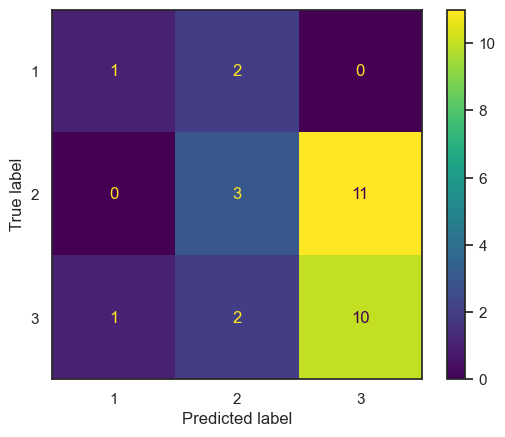

In [19]:
cm = confusion_matrix(
    y_true=y_test,
    y_pred=y_test_pred,
    labels=[1, 2, 3],
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3])
disp.plot()

# Domain of applicability

In [20]:
knn = NearestNeighbors(n_neighbors=5, n_jobs=-1, p=2)
X = df_Xtraining["x_vars"].values.tolist()
knn.fit(X)
con_nbrs = knn.kneighbors(X, return_distance=True, n_neighbors=6)
D = np.mean([np.mean(n[1:]) for n in con_nbrs[0]])
std = np.std([np.mean(n[1:]) for n in con_nbrs[0]])
doa_threshold = D + std * 0.5

In [21]:
samples = df_Xtest["x_vars"].values.tolist()
samples_nbrs = knn.kneighbors(samples, return_distance=True, n_neighbors=5)
df_Xtest["mean_distance"] = [np.mean(n) for n in samples_nbrs[0]]
df_Xtest.loc[
    df_Xtest["mean_distance"] <= doa_threshold,
    "in_domain",
] = True
df_Xtest.loc[
    df_Xtest["mean_distance"] > doa_threshold,
    "in_domain",
] = False

In [22]:
df_Xtest["in_domain"].value_counts()

in_domain
True     24
False     6
Name: count, dtype: int64

In [23]:
df_Xtest["y_pred"] = y_test_pred

y_e = df_Xtest[df_Xtest["in_domain"]]["y"]
y_p = df_Xtest[df_Xtest["in_domain"]]["y_pred"]
recall = recall_score(y_e, y_p, average=None, labels=[1, 2, 3])
dict_results = {
    "balanced_accuracy": balanced_accuracy_score(y_e, y_p),
    "recall_class1": recall[0],
    "recall_class2": recall[1],
    "recall_class3": recall[2],
    "matthews_corrcoef": matthews_corrcoef(y_e, y_p),
}
pd.DataFrame(dict_results, index=[0]).round(2)

,balanced_accuracy,recall_class1,recall_class2,recall_class3,matthews_corrcoef
0,0.32,0.0,0.2,0.75,-0.01


In [24]:
round(len(df_Xtest[df_Xtest["in_domain"] == False]) / len(df_Xtest), 2)

0.2

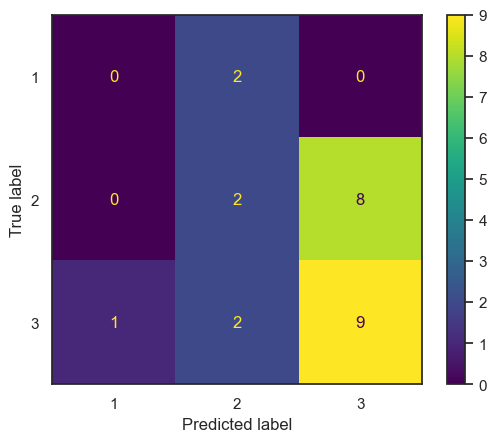

In [25]:
cm = confusion_matrix(
    y_true=y_e,
    y_pred=y_p,
    labels=[1, 2, 3],
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3])
disp.plot()

# UMAP

In [26]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024,
    includeChirality=False,
    useBondTypes=True,
)

morgan_umap = UMAP(
    metric="manhattan",
    random_state=0,
)

In [27]:
df_umap = dilirank_tier2.copy()

df_umap["morgan"] = df_umap["smiles"].apply(
    lambda x: list(mfpgen.GetFingerprint(Chem.MolFromSmiles(x)))
)

X_umap = morgan_umap.fit_transform(df_umap["morgan"].tolist())

umap_cols = ["morgan_umap%s" % (i + 1) for i in range(len(X_umap[0]))]

df_umap[umap_cols] = pd.DataFrame(
    {"UMAP%s" % i: X_umap[:, i] for i in range(len(X_umap[0]))},
    index=df_umap.index,
)

/opt/homebrew/Caskroom/miniconda/base/envs/dili_models/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Axes: xlabel='morgan_umap1', ylabel='morgan_umap2'>

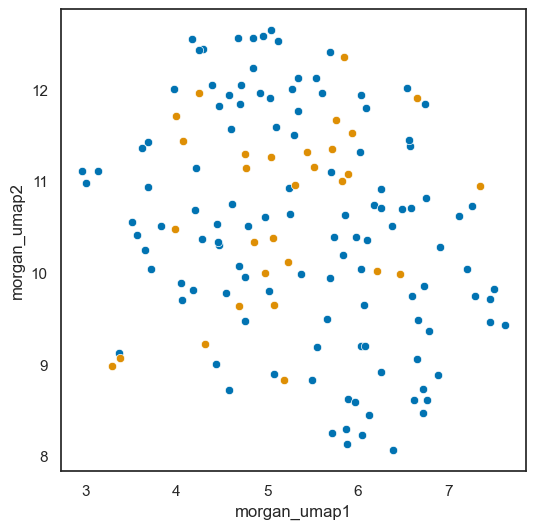

In [28]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    data=df_umap[df_umap[splits_col] != "test"],
    x="morgan_umap1",
    y="morgan_umap2",
    ax=ax,
)
sns.scatterplot(
    data=df_umap[df_umap[splits_col] == "test"],
    x="morgan_umap1",
    y="morgan_umap2",
    ax=ax,
)

In [29]:
X_fit = df_umap[df_umap[splits_col] != "test"][umap_cols]
X_predict = df_umap[df_umap[splits_col] == "test"][umap_cols]

df_dist = pd.DataFrame(
    {
        "X": umap_cols,
        "distances": list(
            map(
                lambda i: ss.ks_2samp(X_fit.iloc[:, i], X_predict.iloc[:, i]).pvalue,
                range(X_fit.shape[1]),
            )
        ),
    }
)

df_dist["distances"].mean().round(2)

0.13

### <span style="color:black"> <b><center> End of the notebook </span></b></center> <a id='test_configuration_file'></a>
***
!-- [Back to Index](#Index) -->